# English to Hindi translation: four model comparison

This notebook builds and compares four translation systems: a basic Transformer, mT5, LLaMA, and Gemma. It uses the same test sentences for all four. The notebook records translation quality, running time, model size, and examples that need human review.

**Run order:** install the packages in `requirements.txt`, run the cells from top to bottom, and let each model finish before starting the next. The laptop has about 8 GB of RAM, so the notebook runs on CPU. The first full model download may take time. This notebook runs once on a fixed 1,000-pair training sample. It is a time-limited CPU experiment, so report the sample size and limits.

Dataset: [IIT Bombay English-Hindi corpus](https://www.cfilt.iitb.ac.in/~moses/iitb_en_hi_parallel/), obtained through [OPUS](https://opus.nlpl.eu/datasets/IITB). See `data/README.md` for cleaning, splits, and license.

## 1. Settings

This notebook makes **one run** using **1,000 training pairs, 100 validation pairs, and 50 shared test pairs**. The basic Transformer and mT5 each train for **one pass** through the training pairs. LLaMA and Gemma use prompting without training. All four models translate the same saved test sentences. These results describe this small sample, not the full database.

Training and testing show progress bars with counts and estimated time left. No widget extension is needed.

In [1]:
from pathlib import Path
import csv, gc, json, os, random, re, statistics, sys, time
import numpy as np
import pandas as pd
import psutil
import torch
import matplotlib.pyplot as plt

ROOT = Path.cwd()
LOCAL_PACKAGES = ROOT / '.deps'
if LOCAL_PACKAGES.is_dir():
    sys.path.insert(0, str(LOCAL_PACKAGES))
DATA = ROOT / 'data' / 'processed'
assert (DATA / 'manifest.json').exists(), 'Open this notebook from the project folder.'
RUN_MODE = 'submit'
SEED = 42
TRAIN_N, DEV_N, TEST_N = 1000, 100, 50
OUT = ROOT / 'results' / RUN_MODE
CKPT = ROOT / 'checkpoints' / RUN_MODE
OUT.mkdir(parents=True, exist_ok=True)
CKPT.mkdir(parents=True, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 1))
print('Mode:', RUN_MODE, '| CPU RAM:', round(psutil.virtual_memory().total / 1024**3, 1), 'GB')
print('PyTorch:', torch.__version__, '| Python:', sys.version.split()[0])
print('Single run: 1,000 training pairs, 100 validation pairs, 50 shared test pairs.')
from IPython.display import HTML, DisplayHandle, display
from html import escape

class StageProgress:
    """A compact progress bar that works without Jupyter widgets."""
    def __init__(self, label, total, unit):
        self.label, self.total, self.unit = label, max(1, int(total)), unit
        self.started = time.perf_counter()
        self.handle = DisplayHandle()
        self.handle.display(HTML(self._render(0, '')))

    @staticmethod
    def _clock(seconds):
        minutes, sec = divmod(int(max(0, seconds)), 60)
        hours, minutes = divmod(minutes, 60)
        return f'{hours}h {minutes}m' if hours else f'{minutes}m {sec}s'

    def _render(self, done, detail):
        pct = min(100, round(100 * done / self.total, 1))
        elapsed = time.perf_counter() - self.started
        remaining = elapsed * (self.total - done) / done if done else None
        timing = f'Elapsed {self._clock(elapsed)}'
        if remaining is not None and done < self.total:
            timing += f' · About {self._clock(remaining)} left'
        return (f'<div style="max-width:620px;font-family:Arial,sans-serif;margin:6px 0">'
                f'<strong>{escape(self.label)}</strong> · {done:,}/{self.total:,} {escape(self.unit)} · {pct}%<br>'
                f'<progress value="{done}" max="{self.total}" style="width:100%;height:18px"></progress><br>'
                f'<small>{escape(timing)}{(" · " + escape(detail)) if detail else ""}</small></div>')

    def update(self, done, detail=''):
        self.handle.update(HTML(self._render(min(int(done), self.total), detail)))


Mode: submit | CPU RAM: 7.7 GB
PyTorch: 2.13.0+cpu | Python: 3.13.3
Single run: 1,000 training pairs, 100 validation pairs, 50 shared test pairs.


## 2. Choose the same data for every model

The existing files already contain separate train, validation, and test splits. This cell selects short and medium sentences that fit the CPU experiment. It saves the original row numbers, so the exact sample can be reproduced. No test sentence is used for training or as a prompt example.

In [2]:
def usable(row):
    en, hi = row['english'], row['hindi']
    return (5 <= len(en) <= 180 and 5 <= len(hi) <= 280
            and re.search(r'[A-Za-z]', en) and re.search(r'[\u0900-\u097F]', hi))

def sample_tsv(path, wanted, seed):
    rng = random.Random(seed)
    chosen, eligible = [], 0
    with path.open('r', encoding='utf-8', newline='') as f:
        for row_id, row in enumerate(csv.DictReader(f, delimiter='\t')):
            if not usable(row):
                continue
            eligible += 1
            item = {'row_id': row_id, 'english': row['english'], 'hindi': row['hindi']}
            if wanted is None or len(chosen) < wanted:
                chosen.append(item)
            else:
                j = rng.randrange(eligible)
                if j < wanted:
                    chosen[j] = item
    if wanted is not None and len(chosen) < wanted:
        raise ValueError(f'Only {len(chosen)} eligible pairs found in {path.name}')
    return pd.DataFrame(sorted(chosen, key=lambda x: x['row_id'])), eligible

train, train_eligible = sample_tsv(DATA / 'iitb_en_hi_train.tsv', TRAIN_N, SEED)
dev, dev_eligible = sample_tsv(DATA / 'iitb_en_hi_dev.tsv', DEV_N, SEED + 1)
test, test_eligible = sample_tsv(DATA / 'iitb_en_hi_test.tsv', TEST_N, SEED + 2)
for name, frame in [('train', train), ('dev', dev), ('test', test)]:
    frame.to_csv(OUT / f'{name}_subset.tsv', sep='\t', index=False)
manifest = {'mode': RUN_MODE, 'seed': SEED, 'sample_sizes': {'train': len(train), 'dev': len(dev), 'test': len(test)},
            'eligible_counts': {'train': train_eligible, 'dev': dev_eligible, 'test': test_eligible},
            'selection': '5-180 English characters; 5-280 Hindi characters; English letters and Devanagari required',
            'row_ids': {name: frame.row_id.tolist() for name, frame in [('train', train), ('dev', dev), ('test', test)]}}
(OUT / 'subset_manifest.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')
print(manifest['sample_sizes'], '| eligible:', manifest['eligible_counts'])
display(train[['english', 'hindi']].head(5))

{'train': 1000, 'dev': 100, 'test': 50} | eligible: {'train': 1005335, 'dev': 55322, 'test': 56248}


,english,hindi
0,Invalid input format,अवैध दिनांक
1,_ Toggle Flag,चिन्हित किए हुओं को टागल करें
2,Next unread,अगला अपठित
3,Please add files to the project.,कृपया फाइल को परियोजना में जोड़ें.
4,The description you provided for the crash is ...,इस क्रैश के लिए दिया विवरण बहुत छोटा है. क्या ...


## 3. Quick data review

Check a few pairs and sentence lengths before training. The selection rule above keeps the experiment manageable; it does not guarantee that every translation is correct. The results describe this short-sentence sample.

,split,pairs,median English characters,median Hindi characters,max English characters,max Hindi characters
0,train,1000,50,51,180,248
1,dev,100,54,55,174,188
2,test,50,62,51,176,168


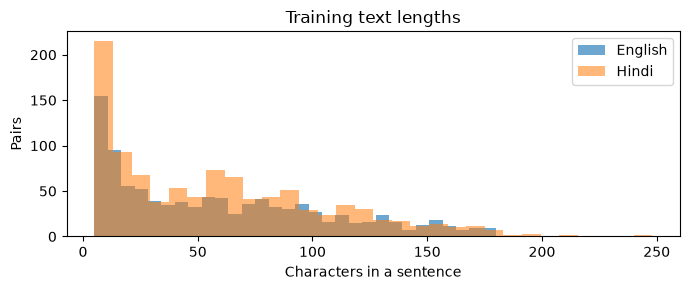

In [3]:
length_rows = []
for name, frame in [('train', train), ('dev', dev), ('test', test)]:
    length_rows.append({'split': name, 'pairs': len(frame),
                        'median English characters': int(frame.english.str.len().median()),
                        'median Hindi characters': int(frame.hindi.str.len().median()),
                        'max English characters': int(frame.english.str.len().max()),
                        'max Hindi characters': int(frame.hindi.str.len().max())})
display(pd.DataFrame(length_rows))
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(train.english.str.len(), bins=30, alpha=.65, label='English')
ax.hist(train.hindi.str.len(), bins=30, alpha=.55, label='Hindi')
ax.set(xlabel='Characters in a sentence', ylabel='Pairs', title='Training text lengths')
ax.legend(); fig.tight_layout()
fig.savefig(OUT / 'sentence_lengths.png', dpi=150)
plt.show()

## 4. Basic Transformer

This model learns translation from the selected pairs. Its encoder reads English; its decoder writes Hindi. We build a small shared vocabulary from **training text only**. The validation and test text never enters vocabulary training.

In [4]:
from tokenizers import Tokenizer, models, pre_tokenizers, decoders, trainers
from torch import nn
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F

special = ['[PAD]', '[BOS]', '[EOS]', '[UNK]']
tokenizer = Tokenizer(models.BPE(unk_token='[UNK]'))
tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
tokenizer.decoder = decoders.ByteLevel()
trainer = trainers.BpeTrainer(vocab_size=8000, min_frequency=2, special_tokens=special,
                             initial_alphabet=pre_tokenizers.ByteLevel.alphabet())
tokenizer.train_from_iterator((text for row in train.itertuples() for text in (row.english, row.hindi)),
                              trainer=trainer, length=2 * len(train))
tokenizer.save(str(CKPT / 'basic_tokenizer.json'))
PAD, BOS, EOS, UNK = [tokenizer.token_to_id(x) for x in special]

length_sample = train.sample(min(1000, len(train)), random_state=SEED)
src_lengths = [len(tokenizer.encode(x).ids) + 1 for x in length_sample.english]
tgt_lengths = [len(tokenizer.encode(x).ids) + 2 for x in length_sample.hindi]
SRC_LIMIT = min(128, max(32, int(np.percentile(src_lengths, 95))))
TGT_LIMIT = min(128, max(32, int(np.percentile(tgt_lengths, 95))))
GEN_LIMIT = min(64, TGT_LIMIT - 1)
print('Vocabulary:', tokenizer.get_vocab_size(), '| English token limit:', SRC_LIMIT,
      '| Hindi token limit:', TGT_LIMIT, '| generation limit:', GEN_LIMIT)
print('Approximate source truncation:', round(np.mean(np.array(src_lengths) > SRC_LIMIT) * 100, 1), '%')
print('Approximate target truncation:', round(np.mean(np.array(tgt_lengths) > TGT_LIMIT) * 100, 1), '%')

Vocabulary: 4188 | English token limit: 42 | Hindi token limit: 100 | generation limit: 64
Approximate source truncation: 4.5 %
Approximate target truncation: 4.8 %


In [5]:
def encode_text(text, limit, target=False):
    ids = tokenizer.encode(text).ids
    return ([BOS] + ids[:limit-2] + [EOS]) if target else (ids[:limit-1] + [EOS])

class PairDataset(Dataset):
    def __init__(self, frame):
        self.rows = [(encode_text(r.english, SRC_LIMIT), encode_text(r.hindi, TGT_LIMIT, True))
                     for r in frame.itertuples()]
    def __len__(self): return len(self.rows)
    def __getitem__(self, i): return self.rows[i]

def pair_batch(rows):
    srcs, tgts = zip(*rows)
    src = torch.full((len(rows), max(map(len, srcs))), PAD, dtype=torch.long)
    tgt = torch.full((len(rows), max(map(len, tgts))), PAD, dtype=torch.long)
    for i, (s, t) in enumerate(rows):
        src[i, :len(s)] = torch.tensor(s)
        tgt[i, :len(t)] = torch.tensor(t)
    return src, tgt

class BasicTransformer(nn.Module):
    def __init__(self, vocab, width=256, heads=4, layers=2, ff=512):
        super().__init__()
        self.scale = width ** .5
        self.words = nn.Embedding(vocab, width, padding_idx=PAD)
        self.positions = nn.Embedding(512, width)
        self.core = nn.Transformer(d_model=width, nhead=heads, num_encoder_layers=layers,
                                   num_decoder_layers=layers, dim_feedforward=ff,
                                   dropout=.1, batch_first=True)
        self.output = nn.Linear(width, vocab)
    def embed(self, ids):
        pos = torch.arange(ids.size(1), device=ids.device).unsqueeze(0)
        return self.words(ids) * self.scale + self.positions(pos)
    def forward(self, src, tgt_in):
        causal = torch.triu(torch.ones(tgt_in.size(1), tgt_in.size(1),
                                      dtype=torch.bool, device=tgt_in.device), diagonal=1)
        hidden = self.core(self.embed(src), self.embed(tgt_in), tgt_mask=causal,
                           src_key_padding_mask=src.eq(PAD), tgt_key_padding_mask=tgt_in.eq(PAD),
                           memory_key_padding_mask=src.eq(PAD))
        return self.output(hidden)

basic = BasicTransformer(tokenizer.get_vocab_size())
basic_params = sum(p.numel() for p in basic.parameters())
print('Basic Transformer parameters:', f'{basic_params:,}')

Basic Transformer parameters: 4,916,316


In [6]:
basic_train = DataLoader(PairDataset(train), batch_size=16,
                         shuffle=True, collate_fn=pair_batch)
basic_dev = DataLoader(PairDataset(dev), batch_size=16, shuffle=False, collate_fn=pair_batch)
basic_opt = torch.optim.AdamW(basic.parameters(), lr=3e-4)
BASIC_EPOCHS = 1  # One full pass through the selected training pairs.

def basic_epoch(loader, training):
    basic.train(training)
    losses = []
    total_batches = len(loader)
    bar = StageProgress('Basic Transformer training' if training else 'Validation',
                        total_batches, 'batches')
    for batch_number, (src, tgt) in enumerate(loader, 1):
        with torch.set_grad_enabled(training):
            logits = basic(src, tgt[:, :-1])
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)),
                                   tgt[:, 1:].reshape(-1), ignore_index=PAD)
            if training:
                basic_opt.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(basic.parameters(), 1.0)
                basic_opt.step()
        losses.append(loss.item())
        if batch_number == 1 or batch_number % (25 if training else 10) == 0 or batch_number == total_batches:
            bar.update(batch_number, f'Latest loss {loss.item():.3f}')
    return statistics.mean(losses)

basic_history = []
print(f'Starting one training epoch: {len(basic_train)} batches.', flush=True)
start = time.perf_counter()
for epoch in range(1, BASIC_EPOCHS + 1):
    tr_loss = basic_epoch(basic_train, True)
    val_loss = basic_epoch(basic_dev, False)
    basic_history.append({'epoch': epoch, 'train_loss': tr_loss, 'val_loss': val_loss})
    print(f'Epoch {epoch}: train loss {tr_loss:.3f}, validation loss {val_loss:.3f}', flush=True)
basic_train_seconds = time.perf_counter() - start
print('Training finished. Saving the model...', flush=True)
torch.save({'state_dict': basic.state_dict(), 'vocab_size': tokenizer.get_vocab_size(),
            'src_limit': SRC_LIMIT, 'tgt_limit': TGT_LIMIT}, CKPT / 'basic_transformer.pt')
pd.DataFrame(basic_history).to_csv(OUT / 'basic_loss.csv', index=False)
print('Training minutes:', round(basic_train_seconds / 60, 2))

Starting one training epoch: 63 batches.


C:\Users\Anuj\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\nn\modules\transformer.py:529: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\NestedTensorImpl.cpp:181.)
  output = torch._nested_tensor_from_mask(


Epoch 1: train loss 5.497, validation loss 4.419


Training finished. Saving the model...


Training minutes: 1.08


## 5. One shared evaluation method

All four models translate the same saved test pairs. The main comparison uses greedy generation, which chooses the most likely next token. A separate section below examines sampling temperature.

In [7]:
TEMP_ROWS = test.head(min(5, len(test))).copy()
run_details = {}

def evaluate_model(name, translate, parameters, training_seconds=None, adaptation=''):
    translate(train.iloc[0].english, 0.0)  # Warm up before timing.
    rows = []
    total = len(test)
    bar = StageProgress(f'{name} test translations', total, 'sentences')
    for number, row in enumerate(test.itertuples(), 1):
        start = time.perf_counter()
        output = translate(row.english, 0.0)
        rows.append({'row_id': row.row_id, 'english': row.english, 'reference': row.hindi,
                     'prediction': output.strip(), 'seconds': time.perf_counter() - start})
        if number == 1 or number % 25 == 0 or number == total:
            pd.DataFrame(rows).to_csv(OUT / f'{name}_predictions.csv', index=False, encoding='utf-8')
            bar.update(number)
    run_details[name] = {'parameters': parameters, 'training_seconds': training_seconds,
                         'adaptation': adaptation}
    print(name, 'finished', len(rows), 'test sentences')

def temperature_examples(name, translate):
    rows = []
    bar = StageProgress(f'{name} temperature examples', len(TEMP_ROWS) * 3, 'translations')
    for row in TEMP_ROWS.itertuples():
        for temp in (0.0, 0.5, 1.0):
            torch.manual_seed(SEED + int(row.row_id) + int(temp * 100))
            rows.append({'model': name, 'row_id': row.row_id, 'temperature': temp,
                         'english': row.english, 'reference': row.hindi,
                         'prediction': translate(row.english, temp).strip()})
            bar.update(len(rows))
    pd.DataFrame(rows).to_csv(OUT / f'{name}_temperature.csv', index=False, encoding='utf-8')

In [8]:
@torch.inference_mode()
def basic_translate(text, temperature=0.0):
    basic.eval()
    src = torch.tensor([encode_text(text, SRC_LIMIT)])
    output = torch.tensor([[BOS]])
    for _ in range(GEN_LIMIT):
        logits = basic(src, output)[0, -1]
        if temperature == 0:
            next_id = int(logits.argmax())
        else:
            next_id = int(torch.multinomial(torch.softmax(logits / temperature, dim=-1), 1))
        if next_id == EOS: break
        output = torch.cat([output, torch.tensor([[next_id]])], dim=1)
    return tokenizer.decode(output[0].tolist(), skip_special_tokens=True)

evaluate_model('basic', basic_translate, basic_params, basic_train_seconds, 'trained from scratch')
temperature_examples('basic', basic_translate)
del basic, basic_opt, basic_train, basic_dev
gc.collect()

basic finished 50 test sentences


81

## 6. Fine-tune mT5

mT5 already knows many languages, but its base checkpoint has not been taught this translation task. We fine-tune it on the selected training pairs. LoRA updates a small part of the model to save memory on this laptop. The code saves the adapter and reports how many pairs it saw.

In [9]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from peft import LoraConfig, TaskType, get_peft_model

MT5_ID = 'google/mt5-small'
mt5_tokenizer = AutoTokenizer.from_pretrained(MT5_ID)
mt5_base = AutoModelForSeq2SeqLM.from_pretrained(MT5_ID, dtype=torch.float32)
mt5 = get_peft_model(mt5_base, LoraConfig(task_type=TaskType.SEQ_2_SEQ_LM,
                                            r=8, lora_alpha=16, lora_dropout=0.05,
                                            target_modules=['q', 'v']))
mt5_total_params = sum(p.numel() for p in mt5.parameters())
mt5_trainable_params = sum(p.numel() for p in mt5.parameters() if p.requires_grad)
prefix = 'translate English to Hindi: '
sample = train.sample(min(500, len(train)), random_state=SEED)
mt5_src_lengths = [len(mt5_tokenizer(prefix + x).input_ids) for x in sample.english]
mt5_tgt_lengths = [len(mt5_tokenizer(x).input_ids) for x in sample.hindi]
MT5_SRC_LIMIT = min(128, max(32, int(np.percentile(mt5_src_lengths, 95))))
MT5_TGT_LIMIT = min(128, max(32, int(np.percentile(mt5_tgt_lengths, 95))))
print('mT5 total parameters:', f'{mt5_total_params:,}', '| trainable:', f'{mt5_trainable_params:,}')
print('mT5 token limits:', MT5_SRC_LIMIT, MT5_TGT_LIMIT)

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


mT5 total parameters: 300,520,832 | trainable: 344,064
mT5 token limits: 45 62


In [10]:
class TextRows(Dataset):
    def __init__(self, frame): self.rows = list(zip(frame.english, frame.hindi))
    def __len__(self): return len(self.rows)
    def __getitem__(self, i): return self.rows[i]

def mt5_batch(rows):
    english, hindi = zip(*rows)
    encoded = mt5_tokenizer([prefix + x for x in english], padding=True, truncation=True,
                            max_length=MT5_SRC_LIMIT, return_tensors='pt')
    targets = mt5_tokenizer(text_target=list(hindi), padding=True, truncation=True,
                            max_length=MT5_TGT_LIMIT, return_tensors='pt').input_ids
    targets[targets == mt5_tokenizer.pad_token_id] = -100
    encoded['labels'] = targets
    return encoded

mt5_loader = DataLoader(TextRows(train), batch_size=1, shuffle=True, collate_fn=mt5_batch)
mt5_val_loader = DataLoader(TextRows(dev.head(min(50, len(dev)))), batch_size=1,
                            shuffle=False, collate_fn=mt5_batch)
mt5_opt = torch.optim.AdamW((p for p in mt5.parameters() if p.requires_grad), lr=3e-4)
mt5.train()
mt5_loss_log = []
mt5_seen = 0
start = time.perf_counter()
mt5_total_steps = len(mt5_loader)
mt5_bar = StageProgress('mT5 training', mt5_total_steps, 'pairs')
for step, batch in enumerate(mt5_loader, 1):
    mt5_opt.zero_grad()
    loss = mt5(**batch).loss
    loss.backward()
    torch.nn.utils.clip_grad_norm_((p for p in mt5.parameters() if p.requires_grad), 1.0)
    mt5_opt.step()
    mt5_seen += len(batch['input_ids'])
    if step == 1 or step % 50 == 0 or step == mt5_total_steps:
        mt5_loss_log.append({'step': step, 'train_loss': loss.item()})
        mt5_bar.update(step, f'Latest loss {loss.item():.3f}')
    if step % 250 == 0:
        mt5.save_pretrained(CKPT / 'mt5_lora')
mt5_train_seconds = time.perf_counter() - start
mt5.eval()
with torch.inference_mode():
    mt5_val_bar = StageProgress('mT5 validation', len(mt5_val_loader), 'batches')
    val_losses = []
    for number, batch in enumerate(mt5_val_loader, 1):
        val_losses.append(float(mt5(**batch).loss))
        if number == 1 or number % 10 == 0 or number == len(mt5_val_loader):
            mt5_val_bar.update(number)
mt5.save_pretrained(CKPT / 'mt5_lora')
mt5_tokenizer.save_pretrained(CKPT / 'mt5_lora')
pd.DataFrame(mt5_loss_log).to_csv(OUT / 'mt5_loss.csv', index=False)
print('Pairs seen:', mt5_seen, '| training minutes:', round(mt5_train_seconds / 60, 2),
      '| validation loss:', round(statistics.mean(val_losses), 3))

Pairs seen: 1000 | training minutes: 10.32 | validation loss: 5.92


In [11]:
@torch.inference_mode()
def mt5_translate(text, temperature=0.0):
    mt5.eval()
    encoded = mt5_tokenizer(prefix + text, return_tensors='pt', truncation=True,
                            max_length=MT5_SRC_LIMIT)
    args = {'max_new_tokens': GEN_LIMIT, 'num_beams': 1, 'do_sample': temperature > 0}
    if temperature > 0:
        args['temperature'] = temperature
    output = mt5.generate(**encoded, **args)
    return mt5_tokenizer.decode(output[0], skip_special_tokens=True)

evaluate_model('mt5', mt5_translate, mt5_total_params, mt5_train_seconds,
               f'LoRA fine-tuning; {mt5_trainable_params:,} trainable parameters; {mt5_seen:,} pairs seen')
temperature_examples('mt5', mt5_translate)
del mt5, mt5_base, mt5_opt, mt5_loader, mt5_val_loader
gc.collect()

mt5 finished 50 test sentences


2598

## 7. Prompt LLaMA and Gemma on CPU

The assignment allows prompting for these two models. Both receive the same two training examples and the same instruction: return only the Hindi translation. A local `llama.cpp` server loads one small, quantized model at a time. This project includes a portable Windows CPU runner in `.tools/llama/bin`. If that folder is missing on another computer, install `llama.cpp` with `winget install llama.cpp`. The first model run downloads its weights; allow time and disk space. Use the model terms shown on their download pages.

In [12]:
import shutil, subprocess, urllib.request, urllib.error

examples = train[train.english.str.len().between(20, 100)].head(2)
assert len(examples) == 2, 'Need two training examples for the prompt.'
few_shot = [(r.english, r.hindi) for r in examples.itertuples()]
(OUT / 'prompt_examples.json').write_text(json.dumps(few_shot, ensure_ascii=False, indent=2), encoding='utf-8')

def make_prompt(text):
    lines = ['Translate the English sentence into Hindi. Return only the Hindi translation.', '']
    for en, hi in few_shot:
        lines += [f'English: {en}', f'Hindi: {hi}', '']
    lines += [f'English: {text}', 'Hindi:']
    return '\n'.join(lines)

PORT = 8089
SERVER_URL = f'http://127.0.0.1:{PORT}'

def start_server(model_id, log_name):
    local_server = ROOT / '.tools' / 'llama' / 'bin' / 'llama-server.exe'
    if local_server.exists():
        command = [str(local_server), '-hf', model_id]
    elif shutil.which('llama'):
        command = [shutil.which('llama'), 'serve', '-hf', model_id]
    elif shutil.which('llama-server'):
        command = [shutil.which('llama-server'), '-hf', model_id]
    else:
        raise RuntimeError('Install llama.cpp with winget install llama.cpp, then rerun this cell.')
    log = (OUT / log_name).open('w', encoding='utf-8')
    command += ['--host', '127.0.0.1', '--port', str(PORT), '-c', '1024', '-ngl', '0']
    print('Starting model server:', model_id, flush=True)
    process = subprocess.Popen(command, stdout=log, stderr=subprocess.STDOUT)
    deadline = time.time() + 1800  # First run may need to download model weights.
    while time.time() < deadline:
        if process.poll() is not None:
            log.close()
            raise RuntimeError(f'Model server stopped. Read {OUT / log_name}')
        try:
            with urllib.request.urlopen(SERVER_URL + '/health', timeout=2) as response:
                if response.status == 200:
                    print('Model server ready:', model_id, flush=True)
                    return process, log
        except (urllib.error.URLError, TimeoutError):
            pass
        time.sleep(2)
    process.terminate(); log.close()
    raise TimeoutError(f'Model server did not become ready. Read {OUT / log_name}')

def stop_server(process, log):
    process.terminate()
    try: process.wait(timeout=20)
    except subprocess.TimeoutExpired: process.kill()
    log.close()

def local_translate(model_id, text, temperature=0.0):
    payload = {'model': model_id, 'messages': [{'role': 'user', 'content': make_prompt(text)}],
               'max_tokens': GEN_LIMIT, 'temperature': temperature, 'seed': SEED,
               'stream': False}
    req = urllib.request.Request(SERVER_URL + '/v1/chat/completions',
                                 data=json.dumps(payload).encode('utf-8'),
                                 headers={'Content-Type': 'application/json'})
    with urllib.request.urlopen(req, timeout=600) as response:
        result = json.load(response)
    return result['choices'][0]['message']['content'].strip()

In [13]:
LLAMA_ID = 'bartowski/Llama-3.2-1B-Instruct-GGUF:Q4_K_M'
llama_process, llama_log = start_server(LLAMA_ID, 'llama_server.log')
try:
    def llama_translate(text, temperature=0.0):
        return local_translate(LLAMA_ID, text, temperature)
    evaluate_model('llama', llama_translate, 1_230_000_000, None,
                   'two-shot prompting; Q4_K_M; approximate published parameter count')
    temperature_examples('llama', llama_translate)
finally:
    stop_server(llama_process, llama_log)

Starting model server: bartowski/Llama-3.2-1B-Instruct-GGUF:Q4_K_M


Model server ready: bartowski/Llama-3.2-1B-Instruct-GGUF:Q4_K_M


llama finished 50 test sentences


In [14]:
GEMMA_ID = 'ggml-org/gemma-3-1b-it-GGUF:Q4_K_M'
gemma_process, gemma_log = start_server(GEMMA_ID, 'gemma_server.log')
try:
    def gemma_translate(text, temperature=0.0):
        return local_translate(GEMMA_ID, text, temperature)
    evaluate_model('gemma', gemma_translate, 1_000_000_000, None,
                   'two-shot prompting; Q4_K_M; approximate published parameter count')
    temperature_examples('gemma', gemma_translate)
finally:
    stop_server(gemma_process, gemma_log)

Starting model server: ggml-org/gemma-3-1b-it-GGUF:Q4_K_M


Model server ready: ggml-org/gemma-3-1b-it-GGUF:Q4_K_M


gemma finished 50 test sentences


## 8. Compare the four systems

BLEU and chrF compare each generated translation with the reference Hindi sentence. Higher scores are better. The time column measures generation on the same test sentences, after one warm-up sentence. Training time is reported only for the models we trained or fine-tuned.

SacreBLEU BLEU: nrefs:1|case:mixed|eff:no|tok:13a|smooth:exp|version:2.6.0 | chrF: nrefs:1|case:mixed|eff:yes|nc:6|nw:0|space:no|version:2.6.0


,model,architecture,BLEU,chrF,parameters,training_minutes,median_inference_seconds,total_inference_minutes,adaptation
0,basic,encoder-decoder,0.00,3.47,4916316,1.08,0.744,0.64,trained from scratch
1,mt5,encoder-decoder,0.06,3.35,300520832,10.32,3.857,2.60,"LoRA fine-tuning; 344,064 trainable parameters..."
2,llama,decoder-only,3.51,14.40,1230000000,NaN,1.365,1.41,two-shot prompting; Q4_K_M; approximate publis...
3,gemma,decoder-only,6.69,26.88,1000000000,NaN,2.366,2.15,two-shot prompting; Q4_K_M; approximate publis...


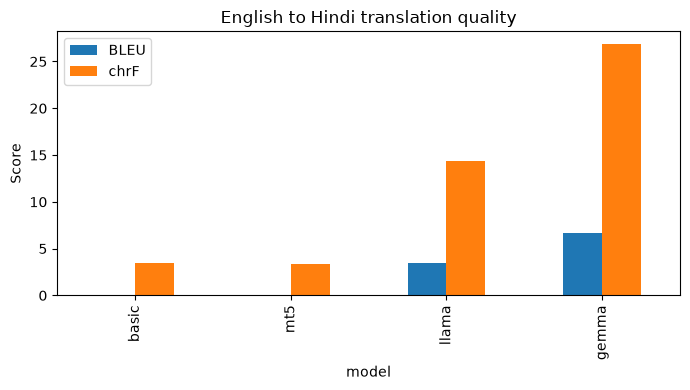

In [15]:
from sacrebleu.metrics import BLEU, CHRF

scores = []
joined = test[['row_id', 'english', 'hindi']].rename(columns={'hindi': 'reference'}).copy()
for name in ('basic', 'mt5', 'llama', 'gemma'):
    path = OUT / f'{name}_predictions.csv'
    if not path.exists():
        raise FileNotFoundError(f'Run the {name} model section first: {path}')
    pred = pd.read_csv(path).fillna('')
    if pred.row_id.tolist() != test.row_id.tolist():
        raise ValueError(f'{name} used a different test set')
    bleu = BLEU()
    chrf = CHRF()
    bleu_score = bleu.corpus_score(pred.prediction.tolist(), [pred.reference.tolist()]).score
    chrf_score = chrf.corpus_score(pred.prediction.tolist(), [pred.reference.tolist()]).score
    info = run_details[name]
    scores.append({'model': name, 'BLEU': round(bleu_score, 2), 'chrF': round(chrf_score, 2),
                   'parameters': info['parameters'], 'training_minutes': None if info['training_seconds'] is None else round(info['training_seconds']/60, 2),
                   'median_inference_seconds': round(float(pred.seconds.median()), 3),
                   'total_inference_minutes': round(float(pred.seconds.sum())/60, 2),
                   'adaptation': info['adaptation']})
    joined[name] = pred.prediction.tolist()

metrics = pd.DataFrame(scores)
metrics.insert(1, 'architecture', metrics.model.map({'basic': 'encoder-decoder', 'mt5': 'encoder-decoder', 'llama': 'decoder-only', 'gemma': 'decoder-only'}))
metrics.to_csv(OUT / 'metrics.csv', index=False)
joined.to_csv(OUT / 'all_translations.csv', index=False, encoding='utf-8')
print('SacreBLEU BLEU:', bleu.get_signature(), '| chrF:', chrf.get_signature())
evaluation_settings = {'mode': RUN_MODE, 'seed': SEED, 'test_row_ids': test.row_id.tolist(),
                       'generation_limit': GEN_LIMIT, 'basic_source_limit': SRC_LIMIT,
                       'mt5_source_limit': MT5_SRC_LIMIT,
                       'BLEU_signature': str(bleu.get_signature()),
                       'chrF_signature': str(chrf.get_signature()),
                       'LLaMA_model': LLAMA_ID, 'Gemma_model': GEMMA_ID,
                       'mT5_model': MT5_ID}
(OUT / 'evaluation_settings.json').write_text(json.dumps(evaluation_settings, indent=2), encoding='utf-8')
display(metrics)
fig, ax = plt.subplots(figsize=(7, 4))
metrics.set_index('model')[['BLEU', 'chrF']].plot.bar(ax=ax)
ax.set(ylabel='Score', title='English to Hindi translation quality')
fig.tight_layout(); fig.savefig(OUT / 'comparison.png', dpi=150)
plt.show()

## 9. Look at examples and sampling temperature

Scores cannot show every error. Read examples from each model side by side. The temperature files show how a model's answer changes when generation is more random. The main scores above always use greedy generation.

In [16]:
review = joined.sample(min(10, len(joined)), random_state=SEED)
review.to_csv(OUT / 'review_samples.csv', index=False, encoding='utf-8')
display(review)
script_check = pd.DataFrame([{'model': name,
                              'outputs without Devanagari': int((~joined[name].fillna('').str.contains(r'[ऀ-ॿ]')).sum())}
                             for name in ('basic', 'mt5', 'llama', 'gemma')])
display(script_check)
temperature_table = pd.concat([pd.read_csv(OUT / f'{name}_temperature.csv').fillna('')
                               for name in ('basic', 'mt5', 'llama', 'gemma')], ignore_index=True)
temperature_table.to_csv(OUT / 'temperature_analysis.csv', index=False, encoding='utf-8')
display(temperature_table[['model', 'temperature', 'english', 'prediction']].head(24))

,row_id,english,reference,basic,mt5,llama,gemma
13,16280,RAM is an ideal son,राम एक आदर्श पुत्र हैं।,्रारारारारारारारारारारारारारारारारारारारारारार...,<extra_id_0> और न जाने और न जाने और न जाने,RAM is a ideal son,RAM एक आदर्श पुत्र है.
39,54796,Only when you come to the question of remunera...,"आशुतोष ने कहा, सिर्फ जब तनख्वाह की बात आती है ...",्रारारारारारारारानानानानानानानानानानानानानानान...,<extra_id_0> और उस और उस और उस और उस और उस और ...,Only when you come to the question of remunera...,"जब सवाल वेतन पर आता है, तो आप दूसरे की तुलना म..."
30,45381,"God has no figure, but because of allure He ca...",वैसे तो ईश्वर रूपहीन है & #44; पर माया की वजह ...,्रारारारारारारारारारारारारारारारारारारारारारार...,<extra_id_0> है। और वह और वह और वह है।,"God has no figure, but because of allure He ca...",मुझे नहीं पता।
45,58483,It urges unity among workers in their struggle...,इसमें अन्याय और शोषण के ख़िलाफ़ मज़दूरों के सं...,्रारारारारारारारारारारारारारारारारानानानानानान...,<extra_id_0> और विकास और विकास और विकास और विक...,It urges unity among workers in their struggle...,यह श्रमिकों को अन्याय और शोषण के खिलाफ उनके सं...
17,24444,A visit to India of the Prince of Wales was an...,"ब्रिटिश राजसिंहासन के वारिस, प्रिंस आफ वेल्स, ...",्रारारारारारारारारारारारारारारारारारारारारारार...,<extra_id_0> और उस युद्ध में जाने और जाने और य...,1921 के नवंबर में इंडिया के राजा वेल्स की यात्...,ब्रिटिश राजकुमार वेलिस की भारत की यात्रा का घो...
48,61771,"A total of 48, 675 hectares of land is used fo...","प्रदेश में 48,675 हेक्टेयर भूमि में खेती की जा...",्रारारारारारारारानानानानानानानानानानानानानानान...,<extra_id_0> और भूमिका के लिए और भूमिका के लिए...,अनुपातिक प्रयोग,"48,675 हेक्टेयर भूमि कृषि के लिए उपयोग में है।"
26,34310,Haiti,हैटी गणराज्य,्रारारारारारारारारारारारारारारारारारारारारारार...,<extra_id_0> और पाकिस्तान,हैत,Hindi: हताखाह
25,33734,placidly,शांतिपूर्वक,्रारारारारारारारारारारारारारारारारारारारारारार...,<extra_id_0> और और और और और और और और और और और ...,"मुझे खेद है, लेकिन मैं व्यक्तिगत रूप से वाक्यो...",शांतভাবে
32,47061,Electronics Hardware Technology Park (EHTP) Sc...,इलेक्ट्रॉनिक्स हार्डवेयर प्रौद्योगिकी पार्क (ई...,्रारारारारारारारारारारारारारारारारारारारारारार...,<extra_id_0> और विकास योजना (आरबी),Electronics Hardware Technology Park (EHTP) Sc...,इलेक्ट्रॉनिक हार्डवेयर प्रौद्योगिकी पार्क (ईएच...
19,24564,Photo,फोटो (P),्रारारारारारारारारारारारारारारारारारारारारारार...,<extra_id_0> और और और और और और और और और और और ...,फोटो,फोटो


,model,outputs without Devanagari
0,basic,0
1,mt5,0
2,llama,14
3,gemma,3


,model,temperature,english,prediction
0,basic,0.0,Error when applying filters,्रारारारारारारारारारारारारारारारारारारारारारार...
1,basic,0.5,Error when applying filters,वेर्रीा्रा म के जी के मम हि के के्याता जाना हा...
2,basic,1.0,Error when applying filters,े जलूातार प फ्च नह
3,basic,0.0,This event has been deleted.,्रारारारारारारारारारारारारारारारारारारारारारार...
4,basic,0.5,This event has been deleted.,्ा की््राक्रीात्रानारारी के की केर् के केताराक...
5,basic,1.0,This event has been deleted.,"ा्ो,ख्ी इनव्रिछाईब जन म aroundान भ"
6,basic,0.0,Mark as _ default task list,्रारारारारारारारारारारारारारारारारानानारानानान...
7,basic,0.5,Mark as _ default task list,का
8,basic,1.0,Mark as _ default task list,"्ें,रजनिेंित क़ाएमे लि म को अपनं पहलतथ ह सचू् ..."
9,basic,0.0,Please browse for a program to execute...,्रारारारारारारारारारारारारारारारारारारारारारार...


## 10. Responsible use and conclusion

**Bias:** Translation may add gender or social assumptions absent from the English sentence. Review pronouns, occupations, and titles with human speakers of Hindi.

**Invented information:** A model can add details or leave out a negation. Compare names, numbers, dates, and the meaning of each sentence with the source. Do not use an unreviewed translation for important decisions.

**Cultural meaning:** Idioms and local terms may be translated literally or lose their intended meaning. Use examples from the intended audience and ask a human reviewer to check them.

**Sensitive content:** Health, legal, and personal information needs extra care. Do not put private text into a service without permission; have qualified people review high-stakes translations.

The table below identifies the highest chrF score on this test set. Discuss the example translations and running time before deciding which model is best for the assignment. The models differ in size, pretraining, tokenization, quantization, and adaptation method, so the scores do not measure architecture alone.

In [17]:
best = metrics.sort_values('chrF', ascending=False).iloc[0]
print(f"Highest chrF on this test set: {best['model']} ({best['chrF']:.2f}).")
encoder = metrics[metrics.architecture == 'encoder-decoder']
decoder = metrics[metrics.architecture == 'decoder-only']
architecture_note = (
    f"In this run, encoder-decoder models averaged chrF {encoder.chrF.mean():.2f} and median inference {encoder.median_inference_seconds.median():.3f} seconds per sentence; "
    f"decoder-only models averaged chrF {decoder.chrF.mean():.2f} and median inference {decoder.median_inference_seconds.median():.3f} seconds per sentence. "
    'These groups also differ in pretraining, parameter count, tokenization, quantization, and adaptation, so this is a descriptive comparison.'
)
temperature_scores = []
for (name, temp), part in temperature_table.groupby(['model', 'temperature'], sort=True):
    score = CHRF().corpus_score(part.prediction.tolist(), [part.reference.tolist()]).score
    greedy = temperature_table[(temperature_table.model == name) &
                                (temperature_table.temperature == 0.0)].set_index('row_id').prediction
    changed = sum(part.set_index('row_id').prediction != greedy.loc[part.row_id].to_numpy())
    temperature_scores.append({'model': name, 'temperature': temp,
                               'chrF on 5 examples': round(score, 2),
                               'outputs changed from greedy': int(changed)})
temperature_summary = pd.DataFrame(temperature_scores)
temperature_summary.to_csv(OUT / 'temperature_summary.csv', index=False)

report = '\n'.join([
    '## Measured results', '',
    'Time-limited CPU run: results reflect a small sample and may not generalize to the full corpus.',
    f'These numbers use the {RUN_MODE} subset: {len(train):,} training, {len(dev):,} validation, and {len(test):,} test pairs.',
    'All four models translated the same test sentences with greedy generation.', '',
    metrics.fillna('N/A').to_markdown(index=False), '',
    '## Architecture comparison', '', architecture_note, '',
    '## Sampling-temperature analysis', '',
    'The following chrF scores use only five examples and show how sampling changes the output. They are illustrative, not the main benchmark.', '',
    temperature_summary.to_markdown(index=False), '',
    'More changed outputs show greater variation; a higher chrF on only five examples does not prove better translation overall.', '',
    '## Responsible use', '',
    'Review the saved examples for added gender assumptions, missing negation, invented names or facts, literal translations of idioms, and errors in sensitive text. Human review is needed for important translations.', '',
    f"The highest chrF on this test set was **{best['model']}** ({best['chrF']:.2f}).",
    'Review the saved translations for meaning, omissions, and bias before making the final choice. The models differ in pretraining, size, tokenization, quantization, and adaptation.', ''
])
(OUT / 'REPORT.md').write_text(report, encoding='utf-8')
readme_path = ROOT / 'README.md'
readme = readme_path.read_text(encoding='utf-8')
left, right = '<!-- RESULTS_START -->', '<!-- RESULTS_END -->'
readme = readme.split(left)[0] + left + '\n' + report + '\n' + right + readme.split(right)[1]
readme_path.write_text(readme, encoding='utf-8')
print('Review review_samples.csv and temperature_analysis.csv before final submission.')
print('Results folder:', OUT.resolve())

Highest chrF on this test set: gemma (26.88).
Review review_samples.csv and temperature_analysis.csv before final submission.
Results folder: C:\Users\Anuj\OneDrive\Documents\ChatGPT\FGAI Final Project\results\submit
